In [1]:
!pip install --upgrade kaggle be-great evidently -qq

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 15.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.1/519.1 kB 21.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 45.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 77.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.2/244.2 kB 15.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.2/88.2 kB 8.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.8/65.8 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 12.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 12.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 22.5 MB/s eta 0:

In [2]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"res1235","key":"aaf1e5bc06a4343766d3104532f9a771"}'}

In [3]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d inversion/crab-age-fine-tuned-gpt2
!unzip crab-age-fine-tuned-gpt2.zip -d crab-age-fine-tuned-gpt2

 98% 432M/441M [00:02<00:00, 156MB/s]
100% 441M/441M [00:03<00:00, 153MB/s]
Archive:  crab-age-fine-tuned-gpt2.zip
  inflating: crab-age-fine-tuned-gpt2/config.json  
  inflating: crab-age-fine-tuned-gpt2/model.pt  


In [5]:
!kaggle datasets download -d sidhus/crab-age-prediction
!unzip crab-age-prediction.zip -d crab-age-prediction

  0% 0.00/81.2k [00:00<?, ?B/s]
100% 81.2k/81.2k [00:00<00:00, 86.4MB/s]
Archive:  crab-age-prediction.zip
  inflating: crab-age-prediction/CrabAgePrediction.csv  


In [1]:
from be_great import GReaT

model_path = '/content/crab-age-fine-tuned-gpt2'

model = GReaT.load_from_dir(model_path)
synthetic_data = model.sample(
    n_samples=1_000,    # change this to generate more samples
    k=50,
    temperature=0.7,  # values between 0.5-0.9 generally give good results
    max_length=256,
    device="cuda")

synthetic_data.to_csv('synthetic_data.csv')
synthetic_data.head()

100%|██████████| 1000/1000 [00:26<00:00, 37.22it/s]


,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
id,,,,,,,,,
0,M,1.4125,1.1250,0.4375,24.692415,9.993199,5.202133,11.056305,20.0
1,F,1.4250,1.1000,0.3125,24.919210,9.964849,5.513978,7.129899,10.0
2,F,1.1875,0.8750,0.3500,16.315137,5.499803,3.600386,5.244657,14.0
3,F,1.7625,1.3625,0.4625,47.513762,21.644843,11.963489,12.459605,11.0
4,F,1.6625,1.3125,0.4250,38.030854,16.782904,8.575724,10.942907,13.0


In [15]:
import pandas as pd

original_data_path = "/content/crab-age-prediction/CrabAgePrediction.csv"
original_data = pd.read_csv(original_data_path)
original_data.head()

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
0,F,1.4375,1.1750,0.4125,24.635715,12.332033,5.584852,6.747181,9
1,M,0.8875,0.6500,0.2125,5.400580,2.296310,1.374951,1.559222,6
2,I,1.0375,0.7750,0.2500,7.952035,3.231843,1.601747,2.764076,6
3,F,1.1750,0.8875,0.2500,13.480187,4.748541,2.282135,5.244657,10
4,I,0.8875,0.6625,0.2125,6.903103,3.458639,1.488349,1.700970,6


In [16]:
from evidently.test_suite import TestSuite
from evidently.test_preset import DataStabilityTestPreset
from evidently.test_preset import DataQualityTestPreset

data_stability= TestSuite(tests=[
    DataStabilityTestPreset(),
])

data_stability.run(current_data=synthetic_data, reference_data=original_data, column_mapping=None)
data_stability

Output hidden; open in https://colab.research.google.com to view.

In [18]:
from evidently.report import Report
from evidently.metric_preset import DataDriftPreset

data_drift_report = Report(metrics=[
    DataDriftPreset(),
])

data_drift_report.run(current_data=synthetic_data, reference_data=original_data, column_mapping=None)
data_drift_report

Output hidden; open in https://colab.research.google.com to view.

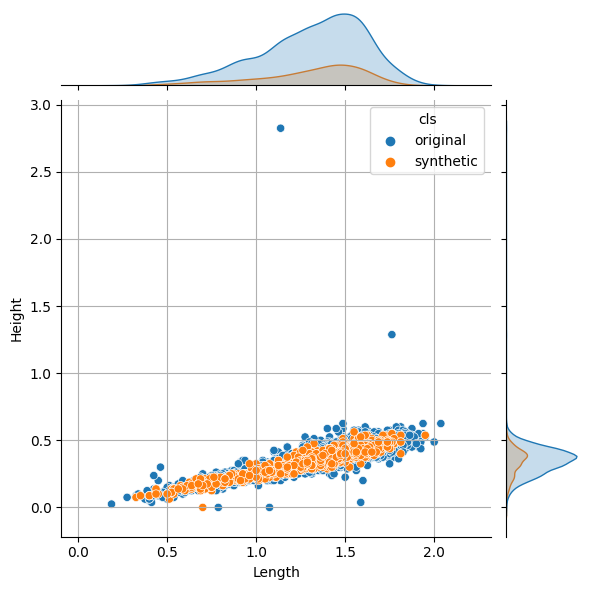

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.concat([original_data, synthetic_data], axis=0)
df['cls']  = ['original']  * len(original_data) + ['synthetic'] * len(synthetic_data)

sns.jointplot(
    data=df,
    x="Length",
    y="Height",
    hue='cls'
)

plt.grid(True)
plt.show()